MSS to capture screenshots. OpenCV to read the frames?? MSS faster than OpenCV. PyDirectInput sends commands to the game. PyTesseract for OCR output checking, instead of it, just check change in color for optimization.


In [102]:
from mss import mss #to capture SS
#import pydirectinput #to issue cmds
import pyautogui #to pass cmds to the game
import     cv2 #openCV for frame processing
import numpy as np
import pytesseract #OCR 
import matplotlib.pyplot as plt
import time


In [103]:
from gymnasium import Env #gymnasium instead of Gym, for env definition
from gymnasium.spaces import Box, Discrete

In [154]:
from gymnasium.spaces import space


class WebGame(Env): #creating RL environment
    def __init__(self): #setup env action and observation
        super().__init__() #subclass model ???

        self.observation_space = Box(low=0, high=255, shape=(1, 83, 125), dtype=np.uint8) #multidimensional array with 0 to 255 values, 83px x 100px
        self.action_space = Discrete(3) #3 actions, space; nothing and down

        self.cap = mss()
        self.game_location = {'top':200, 'left':400, 'width':450, 'height':100}
        self.done_location = {'top':200, 'left':620, 'width':200, 'height':30}


    def step(self, action): #any action in the game
        # 0: space, 2: NA, 1: down key, rewards inaction
        reward = -2

        if action == 0:
            pyautogui.press('up')
        
        elif action == 1:
            pyautogui.press('down')

        else:
            reward = 3


        done, done_cap = self.getDone() #check if done
        new_observation = self.get_observation() #check next observation
        # reward = 1 #point if we alive [EARLY POINT SYS]
        info = {}
        return new_observation, reward, done,False, info


    def render(self): #viz the game
        cv2.imshow('Game', np.array(self.cap.grab(self.game_location))[:, :,:3])
        if cv2.waitKey(1) & 0XFF == ord('q'):
            self.close()

    def reset(self, seed=None):
        info = {}
        time.sleep(1)
        pyautogui.press('space')
        return (self.get_observation(), info)


    def close(self): #closes observation
        cv2.destroyAllWindows()

    def get_observation(self): #get part of the observation of the game
        raw = np.array(self.cap.grab(self.game_location))[:, :, :3]

        gray = cv2.cvtColor(raw, cv2.COLOR_BGR2GRAY)
        resized = cv2.resize(gray, (125, 83))
        channel = np.reshape(resized, (1, 83, 125)) #channels first, for stable baseline
        return channel
    
    def getDone(self): #NEW FUNCTION, only pixel check
        done_cap = np.array(self.cap.grab({'top':210, 'left':625, 'width':1, 'height':1}))[0][0][0]
        done = False
        if done_cap == 172:
            done = True

        return done, done_cap


    def get_done(self): #check if game over
        done_cap = np.array(self.cap.grab(self.done_location))[:, :, :3]
        #valid done text
        done_strings = ['GAME', 'GAHE']
        done = False
        res = pytesseract.image_to_string(done_cap)[:4]
        if res in done_strings:
            done = True
        return done, done_cap

# Testing

In [155]:
env = WebGame()

In [ ]:

print
(env.getDone()[0][0][0]) #getdone is 172 172 172

TypeError: 'bool' object is not subscriptable

In [37]:
obs = env.get_observation()

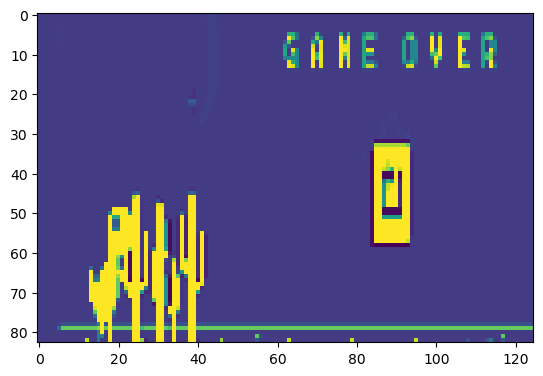

In [38]:
plt.imshow(obs[0])

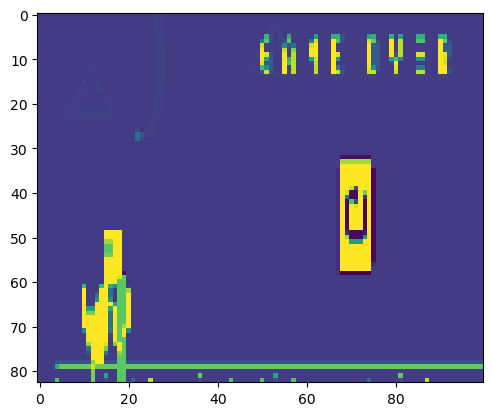

In [6]:
plt.imshow(obs[0])

# Loop


In [7]:
# for episode in range(10):
#     obs = env.reset()
#     done = False
#     total_reward = 0

#     while not done:
#         obs,reward, done, info = env.step(1)
#         total_reward += reward
#     print(f"Total reward for this episode {episode} is {total_reward}")


# MODEL

In [156]:
import os
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common import env_checker

In [157]:
env_checker.check_env(env) #reset method showed problems, seed was passed as none, it now return tuple of size 2, (obs, info) where info is an empty dict

In [158]:
class TrainAndLoggingCallback(BaseCallback):
    def __init__(self, check_freq, save_path, verbose=1):
        super(TrainAndLoggingCallback, self).__init__(verbose)
        self.check_freq = check_freq
        self.save_path = save_path

    def _init_callback(self):
        if self.save_path is not None:
            os.makedirs(self.save_path, exist_ok=True)

    def _on_step(self):
        if self.n_calls % self.check_freq == 0:
            model_path = os.path.join(self.save_path, 'best_model_{}'.format(self.n_calls))
            self.model.save(model_path)

        return True



In [159]:
CHECKPOINT_DIR = './train/'
LOG_DIR = './logs/'

In [160]:

callback = TrainAndLoggingCallback(check_freq=2000, save_path=CHECKPOINT_DIR)

In [161]:
from stable_baselines3 import DQN


In [162]:
model = DQN('CnnPolicy', env, tensorboard_log=LOG_DIR, verbose=1, buffer_size=300_000, learning_starts=1000)


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


In [163]:
model.learn(total_timesteps=5000, callback=callback)

Logging to ./logs/DQN_8
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 19.8     |
|    ep_rew_mean      | -2       |
|    exploration_rate | 0.85     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 4        |
|    time_elapsed     | 16       |
|    total_timesteps  | 79       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 27.2     |
|    ep_rew_mean      | -5.75    |
|    exploration_rate | 0.586    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 5        |
|    time_elapsed     | 41       |
|    total_timesteps  | 218      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 27.2     |
|    ep_rew_mean      | -9.08    |
|    exploration_rate | 0.379    |
| time/               |        

In [165]:
#model=DQN.load(path) if read
for episode in range(1):
    obs, _ = env.reset()
    done = False
    total_reward = 0

    while not done:
        action, _ = model.predict(obs)
        obs,reward, done, _ ,info = env.step(int(action))
        total_reward += reward
    print(f"Total reward for this episode {episode} is {total_reward}")


Total reward for this episode 0 is 553
